# Análisis SQL de Subscribers 2020


In [ ]:
# Instalar pandasql si no lo tienes: pip install pandasql
import pandas as pd
import pandasql as psql
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar gráficos
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)


In [ ]:
# Cargar CSV
df = pd.read_csv(r'C:\Users\Propietario\Downloads\subscribers_2020.csv', sep=';')

# Convertir fechas y calcular duración
df['started_at'] = pd.to_datetime(df['started_at'], format='%d/%m/%Y')
df['ended_at'] = pd.to_datetime(df['ended_at'], format='%d/%m/%Y')
df['duration_days'] = (df['ended_at'] - df['started_at']).dt.days

df.head()


,started_at,ended_at,product_price,product_type,continent,company_user_condition,subscribers
0,01/12/2020,01/12/2024,campaign discount,year,Asia,new,60
1,01/07/2020,01/01/2024,full price,month,Asia,new,15
2,01/12/2020,01/01/2024,full price,month,Europe,new,13
3,01/09/2020,01/12/2023,campaign discount,month,South America,new,3
4,01/05/2020,01/09/2023,full price,month,South America,former,5


In [44]:
# Función para ejecutar SQL
def query(sql):
    return psql.sqldf(sql, globals())

# Función para crear gráficos automáticamente
def plot_query(sql, title, plot_type='bar', x_col=None, y_col=None):
    result = query(sql)
    print(f"\n=== {title} ===")
    print(result)
    
    if plot_type == 'bar':
        if x_col and y_col:
            plt.figure(figsize=(10, 6))
            plt.bar(result[x_col], result[y_col])
            plt.title(title)
            plt.xlabel(x_col)
            plt.ylabel(y_col)
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()
    
    return result



=== Suscriptores por Tipo de Usuario ===
  company_user_condition  registros  total_subscribers  promedio_subscribers  \
0                    new         74               8647                116.85   
1                 former         26                622                 23.92   

   porcentaje  
0       93.29  
1        6.71  


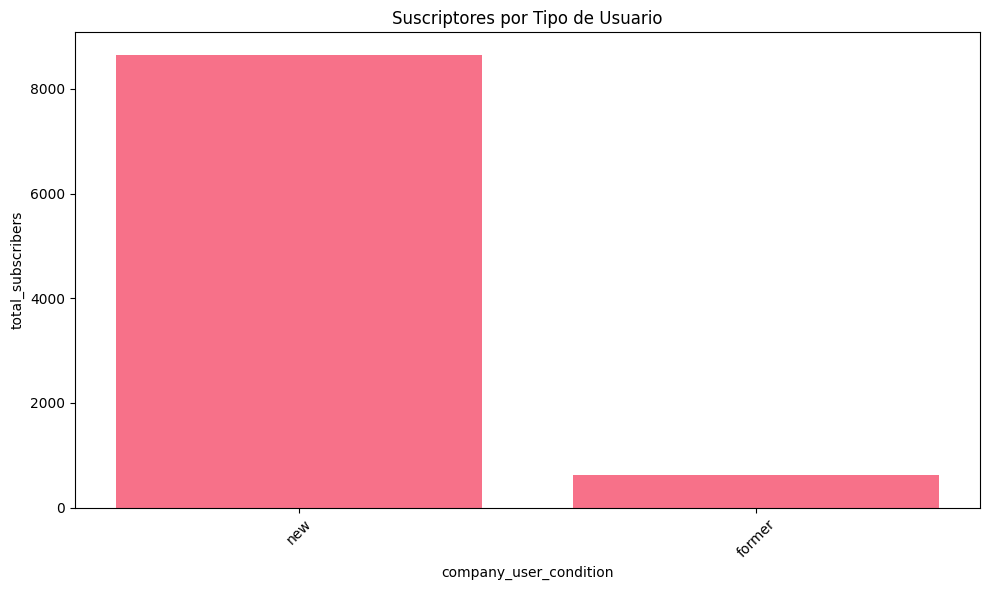

In [49]:
# 1. Suscriptores por tipo de usuario
result1 = plot_query("""
SELECT 
    company_user_condition,
    COUNT(*) as registros,
    SUM(subscribers) as total_subscribers,
    ROUND(AVG(subscribers), 2) as promedio_subscribers,
    ROUND(SUM(subscribers) * 100.0 / (SELECT SUM(subscribers) FROM df), 2) as porcentaje
FROM df 
GROUP BY company_user_condition
ORDER BY total_subscribers DESC
""", "Suscriptores por Tipo de Usuario", 'bar', 'company_user_condition', 'total_subscribers')



=== Suscriptores por Continente ===
       continent  registros  total_subscribers  promedio_subscribers
0           Asia         40               5968                149.20
1  South America         43               1677                 39.00
2         Europe         14               1595                113.93
3         Africa          3                 29                  9.67


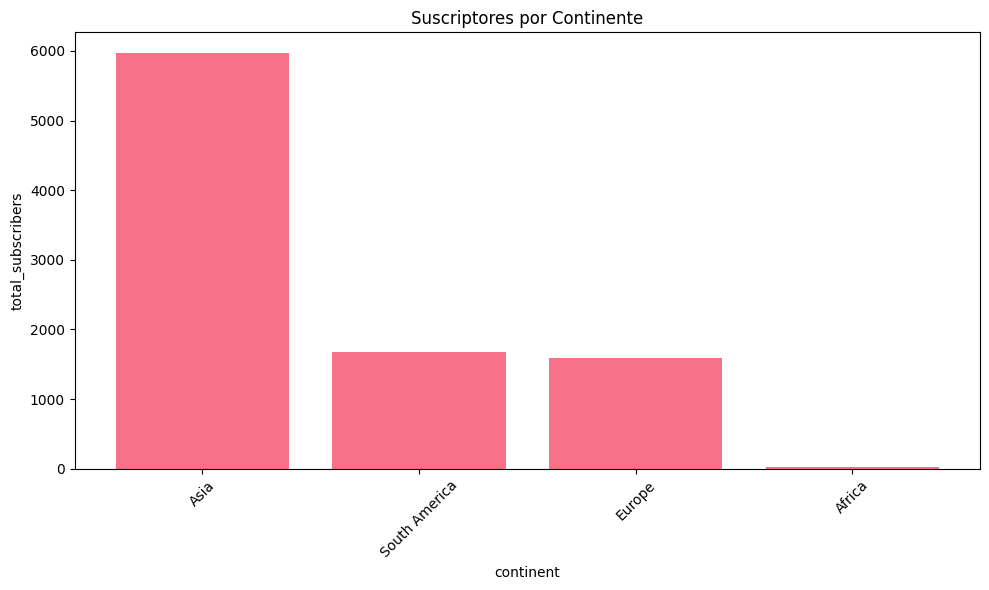

In [45]:
# 2. Análisis por continente
result2 = plot_query("""
SELECT 
    continent,
    COUNT(*) as registros,
    SUM(subscribers) as total_subscribers,
    ROUND(AVG(subscribers), 2) as promedio_subscribers
FROM df 
GROUP BY continent
ORDER BY total_subscribers DESC
""", "Suscriptores por Continente", 'bar', 'continent', 'total_subscribers')



=== Suscriptores por Combinación Producto-Precio ===
                 combinacion  registros  total_subscribers  \
0         month - full price         54               4741   
1   year - campaign discount         11               3031   
2  month - campaign discount         27               1101   
3          year - full price          8                396   

   promedio_subscribers  
0                 87.80  
1                275.55  
2                 40.78  
3                 49.50  


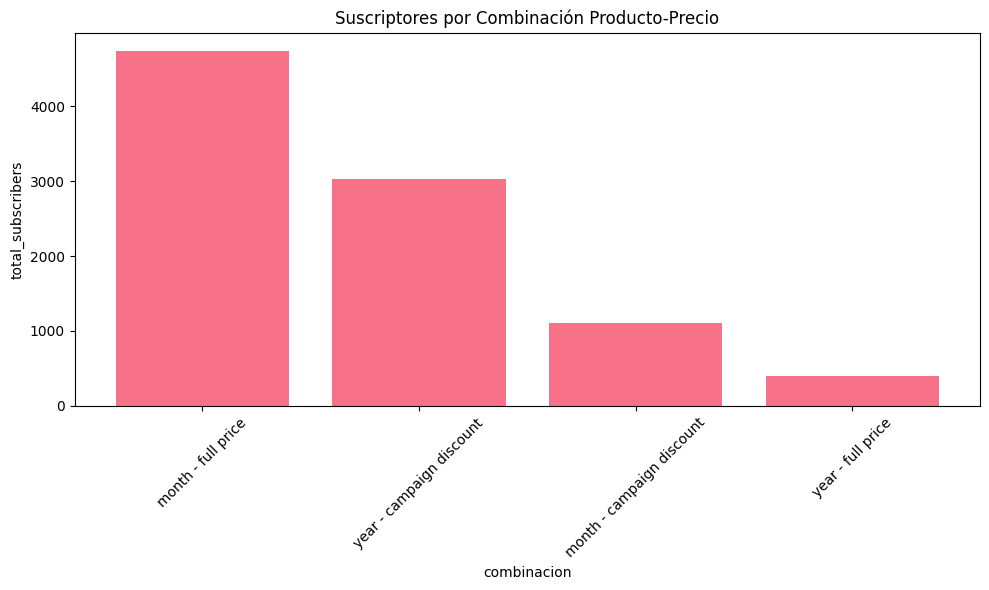

In [46]:
# 3. Combinación producto-precio
result3 = plot_query("""
SELECT 
    product_type || ' - ' || product_price as combinacion,
    COUNT(*) as registros,
    SUM(subscribers) as total_subscribers,
    ROUND(AVG(subscribers), 2) as promedio_subscribers
FROM df 
GROUP BY product_type, product_price
ORDER BY total_subscribers DESC
""", "Suscriptores por Combinación Producto-Precio", 'bar', 'combinacion', 'total_subscribers')


In [ ]:
# 4. Estacionalidad por mes (Asia)
result4 = plot_query("""
SELECT 
    CASE EXTRACT(MONTH FROM started_at)
        WHEN 1 THEN 'Ene'
        WHEN 2 THEN 'Feb'
        WHEN 3 THEN 'Mar'
        WHEN 4 THEN 'Abr'
        WHEN 5 THEN 'May'
        WHEN 6 THEN 'Jun'
        WHEN 7 THEN 'Jul'
        WHEN 8 THEN 'Ago'
        WHEN 9 THEN 'Sep'
        WHEN 10 THEN 'Oct'
        WHEN 11 THEN 'Nov'
        WHEN 12 THEN 'Dic'
    END as mes,
    SUM(subscribers) as total_subscribers,
    ROUND(SUM(subscribers) * 100.0 / (SELECT SUM(subscribers) FROM df WHERE continent = 'Asia'), 1) as porcentaje
FROM df 
WHERE continent = 'Asia'
GROUP BY EXTRACT(MONTH FROM started_at)
ORDER BY EXTRACT(MONTH FROM started_at)
""", "Estacionalidad - Suscriptores Asia por Mes", 'bar', 'mes', 'total_subscribers')


In [48]:
# 5. Análisis de retención
result5 = plot_query("""
SELECT 
    CASE 
        WHEN duration_days < 30 THEN 'Menos de 1 mes'
        WHEN duration_days BETWEEN 30 AND 89 THEN '1-3 meses'
        WHEN duration_days BETWEEN 90 AND 179 THEN '3-6 meses'
        WHEN duration_days BETWEEN 180 AND 365 THEN '6-12 meses'
        WHEN duration_days > 365 THEN 'Más de 12 meses'
    END as rango_duracion,
    COUNT(*) as registros,
    SUM(subscribers) as total_subscribers,
    ROUND(SUM(subscribers) * 100.0 / (SELECT SUM(subscribers) FROM df WHERE product_type = 'month' AND product_price = 'full price' AND company_user_condition = 'new'), 2) as porcentaje
FROM df 
WHERE product_type = 'month' 
  AND product_price = 'full price' 
  AND company_user_condition = 'new'
GROUP BY 
    CASE 
        WHEN duration_days < 30 THEN 'Menos de 1 mes'
        WHEN duration_days BETWEEN 30 AND 89 THEN '1-3 meses'
        WHEN duration_days BETWEEN 90 AND 179 THEN '3-6 meses'
        WHEN duration_days BETWEEN 180 AND 365 THEN '6-12 meses'
        WHEN duration_days > 365 THEN 'Más de 12 meses'
    END
ORDER BY 
    CASE 
        WHEN duration_days < 30 THEN 1
        WHEN duration_days BETWEEN 30 AND 89 THEN 2
        WHEN duration_days BETWEEN 90 AND 179 THEN 3
        WHEN duration_days BETWEEN 180 AND 365 THEN 4
        WHEN duration_days > 365 THEN 5
    END
""", "Análisis de Retención - Usuarios Nuevos Mensuales", 'bar', 'rango_duracion', 'total_subscribers')


PandaSQLException: (sqlite3.OperationalError) no such column: duration_days
[SQL: 
SELECT 
    CASE 
        WHEN duration_days < 30 THEN 'Menos de 1 mes'
        WHEN duration_days BETWEEN 30 AND 89 THEN '1-3 meses'
        WHEN duration_days BETWEEN 90 AND 179 THEN '3-6 meses'
        WHEN duration_days BETWEEN 180 AND 365 THEN '6-12 meses'
        WHEN duration_days > 365 THEN 'Más de 12 meses'
    END as rango_duracion,
    COUNT(*) as registros,
    SUM(subscribers) as total_subscribers,
    ROUND(SUM(subscribers) * 100.0 / (SELECT SUM(subscribers) FROM df WHERE product_type = 'month' AND product_price = 'full price' AND company_user_condition = 'new'), 2) as porcentaje
FROM df 
WHERE product_type = 'month' 
  AND product_price = 'full price' 
  AND company_user_condition = 'new'
GROUP BY 
    CASE 
        WHEN duration_days < 30 THEN 'Menos de 1 mes'
        WHEN duration_days BETWEEN 30 AND 89 THEN '1-3 meses'
        WHEN duration_days BETWEEN 90 AND 179 THEN '3-6 meses'
     

In [ ]:
# 6. Top 10 registros con más suscriptores
result6 = plot_query("""
SELECT 
    continent || ' - ' || product_type || ' - ' || product_price as descripcion,
    subscribers
FROM df 
ORDER BY subscribers DESC
LIMIT 10
""", "Top 10 Registros con Más Suscriptores", 'bar', 'descripcion', 'subscribers')


In [ ]:
# 7. Distribución por continente y condición de usuario
result7 = plot_query("""
SELECT 
    continent,
    company_user_condition,
    SUM(subscribers) as total_subscribers
FROM df 
GROUP BY continent, company_user_condition
ORDER BY continent, total_subscribers DESC
""", "Distribución por Continente y Condición de Usuario", 'bar', 'continent', 'total_subscribers')


In [ ]:
# 8. Gráfico de torta - Distribución por continente
result8 = query("""
SELECT 
    continent,
    SUM(subscribers) as total_subscribers
FROM df 
GROUP BY continent
ORDER BY total_subscribers DESC
""")

print("\n=== Distribución por Continente ===")
print(result8)

plt.figure(figsize=(8, 8))
plt.pie(result8['total_subscribers'], labels=result8['continent'], autopct='%1.1f%%', startangle=90)
plt.title('Distribución de Suscriptores por Continente')
plt.axis('equal')
plt.show()


In [ ]:
# 9. Gráfico de líneas - Evolución temporal
result9 = query("""
SELECT 
    EXTRACT(MONTH FROM started_at) as mes,
    SUM(subscribers) as total_subscribers
FROM df 
GROUP BY EXTRACT(MONTH FROM started_at)
ORDER BY EXTRACT(MONTH FROM started_at)
""")

print("\n=== Evolución Temporal ===")
print(result9)

plt.figure(figsize=(12, 6))
plt.plot(result9['mes'], result9['total_subscribers'], marker='o', linewidth=2, markersize=8)
plt.title('Evolución de Suscriptores por Mes')
plt.xlabel('Mes')
plt.ylabel('Total Suscriptores')
plt.grid(True, alpha=0.3)
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


In [ ]:
# 10. Resumen ejecutivo con métricas clave
print("\n" + "="*50)
print("RESUMEN EJECUTIVO - FREEPIK 2020")
print("="*50)

# Métricas principales
total_subs = query("SELECT SUM(subscribers) as total FROM df")['total'].iloc[0]
total_regs = len(df)
avg_subs = query("SELECT AVG(subscribers) as promedio FROM df")['promedio'].iloc[0]

print(f"📊 Total de suscriptores: {total_subs:,}")
print(f"📈 Total de registros: {total_regs:,}")
print(f"📋 Promedio por registro: {avg_subs:.2f}")

# Top continente
top_continent = query("""
SELECT continent, SUM(subscribers) as total 
FROM df 
GROUP BY continent 
ORDER BY total DESC 
LIMIT 1
""")
print(f"🌍 Continente líder: {top_continent['continent'].iloc[0]} ({top_continent['total'].iloc[0]:,} suscriptores)")

# Top combinación
top_combo = query("""
SELECT product_type, product_price, SUM(subscribers) as total 
FROM df 
GROUP BY product_type, product_price 
ORDER BY total DESC 
LIMIT 1
""")
print(f"💎 Mejor combinación: {top_combo['product_type'].iloc[0]} - {top_combo['product_price'].iloc[0]} ({top_combo['total'].iloc[0]:,} suscriptores)")

print("="*50)


In [21]:
# FORMATO DE LAS COLUMNAS STARTED_AT Y ENDED_AT

# Convertimos las columnas 'started_at' y 'ended_at' al formato de fecha (datetime) para facilitar análisis posteriores.
df['started_at'] = pd.to_datetime(df['started_at'], format='%d/%m/%Y')
df['ended_at'] = pd.to_datetime(df['ended_at'], format='%d/%m/%Y')

# Mostramos las primeras filas para verificar el cambio de formato
df.head()


,started_at,ended_at,product_price,product_type,continent,company_user_condition,subscribers
0,2020-12-01,2024-12-01,campaign discount,year,Asia,new,60
1,2020-07-01,2024-01-01,full price,month,Asia,new,15
2,2020-12-01,2024-01-01,full price,month,Europe,new,13
3,2020-09-01,2023-12-01,campaign discount,month,South America,new,3
4,2020-05-01,2023-09-01,full price,month,South America,former,5


In [ ]:
# Consulta SQL para obtener suscriptores por tipo de usuario
query("""
SELECT 
    company_user_condition,
    SUM(subscribers) as total_subscribers,
    ROUND(SUM(subscribers) * 100.0 / (SELECT SUM(subscribers) FROM df), 2) as porcentaje
FROM df 
WHERE started_at >= '2020-01-01' AND started_at <= '2020-12-31'
GROUP BY company_user_condition
ORDER BY total_subscribers DESC
""")


,company_user_condition,num_registros,total_subscribers,promedio_subscribers,porcentaje
0,new,74,8647,116.85,93.29
1,former,26,622,23.92,6.71


What was the number of subscribers in 2020, broken down by user type (new vs. former)?
 What conclusions do you draw and what measures would you propose to improve the number of subscribers?


Medidas Propuestas:
1. Mejorar Retención de Former Users:
Programa de fidelización con descuentos exclusivos
Re-engagement campaigns para usuarios inactivos
Encuestas para entender por qué se fueron

In [30]:
# Análisis por combinación de período de facturación y precio
query("""
SELECT 
    product_type,
    product_price,
    SUM(subscribers) as total_subscribers
    FROM df 
GROUP BY product_type, product_price
ORDER BY total_subscribers DESC
""")

,product_type,product_price,total_subscribers
0,month,full price,4741
1,year,campaign discount,3031
2,month,campaign discount,1101
3,year,full price,396


Which combination of billing period(month or year) and price (full price or campaign discount) generated the most subscribers?


Conclusión: La combinación month + full price genera más suscriptores (52.32% del total).


Recomendación: Enfocar estrategias en suscripciones mensuales a precio completo para maximizar el volumen total de suscriptores.

In [43]:
query("""
SELECT 
    strftime('%m', DATE(started_at)) as mes,
    SUM(subscribers) as total,
    ROUND(SUM(subscribers) * 100.0 / (SELECT SUM(subscribers) FROM df WHERE continent = 'Asia'), 1) as porcentaje
FROM df 
WHERE continent = 'Asia'
GROUP BY strftime('%m', DATE(started_at))
ORDER BY mes
""")

,mes,total,porcentaje
0,01,176,2.9
1,02,390,6.5
2,03,3,0.1
3,04,642,10.8
4,05,314,5.3
5,06,666,11.2
6,07,391,6.6
7,08,166,2.8
8,09,205,3.4
9,10,324,5.4


What percentage of subscribers from Asia started their subscription in each month of the year?

In [ ]:
What conclusions can you draw about Freepik’s seasonality?

Análisis de estacionalidad de Freepik
Patrones identificados
1. Pico en noviembre (38.5%)
Concentra casi 4 de cada 10 suscriptores
Coincide con Black Friday y preparación navideña
Momento de mayor demanda
2. Temporada alta (octubre–diciembre)
Octubre: 5.4%
Noviembre: 38.5%
Diciembre: 6.6%
Total: 50.5% en Q4
3. Temporada media (abril–junio)
Abril: 10.8%
Mayo: 5.3%
Junio: 11.2%
Total: 27.3% en Q2
4. Temporada baja (enero–marzo)
Enero: 2.9%
Febrero: 6.5%
Marzo: 0.1%
Total: 9.5% en Q1
Conclusiones
Estacionalidad marcada: Q4 concentra la mitad de las suscripciones
Noviembre es el mes crítico
Q1 es el período más débil
Q2 muestra recuperación
Recomendaciones
1. Preparación para noviembre
Ampliar capacidad
Campañas de marketing
Ofertas especiales
2. Estrategias para Q1
Campañas de retención
Promociones de reactivación
Enfoque en mercados menos estacionales
3. Optimización de recursos
Reducir costos en Q1
Maximizar inversión en Q4
Planificar inventario según estacionalidad

In [ ]:
query("""
WITH duraciones AS (
    SELECT 
        CASE 
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) < 30 THEN 'Menos de 1 mes'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 30 AND 59 THEN '1-2 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 60 AND 89 THEN '2-3 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 90 AND 119 THEN '3-4 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 120 AND 149 THEN '4-5 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 150 AND 179 THEN '5-6 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 180 AND 209 THEN '6-7 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 210 AND 239 THEN '7-8 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 240 AND 269 THEN '8-9 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 270 AND 299 THEN '9-10 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 300 AND 329 THEN '10-11 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 330 AND 365 THEN '11-12 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 366 AND 395 THEN '12-13 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 396 AND 425 THEN '13-14 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 426 AND 455 THEN '14-15 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 456 AND 485 THEN '15-16 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 486 AND 515 THEN '16-17 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 516 AND 545 THEN '17-18 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 546 AND 575 THEN '18-19 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 576 AND 605 THEN '19-20 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 606 AND 635 THEN '20-21 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 636 AND 665 THEN '21-22 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 666 AND 695 THEN '22-23 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) BETWEEN 696 AND 725 THEN '23-24 meses'
            WHEN (julianday(COALESCE(ended_at, DATE('now'))) - julianday(started_at)) > 725 THEN 'Más de 24 meses'
        END as rango_duracion,
        subscribers
    FROM df
    WHERE product_type = 'month' 
      AND product_price = 'full price' 
      AND company_user_condition = 'new'
)
SELECT 
    rango_duracion,
    SUM(subscribers) as total_subscribers
FROM duraciones
GROUP BY rango_duracion
ORDER BY 
    CASE rango_duracion
        WHEN 'Más de 24 meses' THEN 25
        WHEN '23-24 meses' THEN 24
        WHEN '22-23 meses' THEN 23
        WHEN '21-22 meses' THEN 22
        WHEN '20-21 meses' THEN 21
        WHEN '19-20 meses' THEN 20
        WHEN '18-19 meses' THEN 19
        WHEN '17-18 meses' THEN 18
        WHEN '16-17 meses' THEN 17
        WHEN '15-16 meses' THEN 16
        WHEN '14-15 meses' THEN 15
        WHEN '13-14 meses' THEN 14
        WHEN '12-13 meses' THEN 13
        WHEN '11-12 meses' THEN 12
        WHEN '10-11 meses' THEN 11
        WHEN '9-10 meses' THEN 10
        WHEN '8-9 meses' THEN 9
        WHEN '7-8 meses' THEN 8
        WHEN '6-7 meses' THEN 7
        WHEN '5-6 meses' THEN 6
        WHEN '4-5 meses' THEN 5
        WHEN '3-4 meses' THEN 4
        WHEN '2-3 meses' THEN 3
        WHEN '1-2 meses' THEN 2
        WHEN 'Menos de 1 mes' THEN 1
        ELSE 0
    END DESC
""")

,rango_duracion,total_subscribers
0,Más de 12 meses,911
1,11-12 meses,23
2,10-11 meses,5
3,9-10 meses,109
4,8-9 meses,14
5,7-8 meses,101
6,5-6 meses,161
7,4-5 meses,975
8,2-3 meses,2045


In [ ]:
Análisis de retención
Patrones
2–3 meses: 2,045 suscriptores (pico)
4–5 meses: 975
Más de 12 meses: 911
5–6 meses: 161
Problemas
Caída fuerte tras 2–3 meses
Poca retención a largo plazo
Pérdida de usuarios en 3–6 meses
Estrategias de mejora
1. Programa de onboarding (0–3 meses)
Tutorial interactivo
Contenido gratuito
Soporte prioritario
Recordatorios de uso
2. Campañas de re-engagement (3–6 meses)
Emails con casos de uso
Webinars
Descuentos por renovación
Encuestas de satisfacción
3. Programa de fidelización (6+ meses)
Beneficios por antigüedad
Acceso anticipado a nuevas funciones
Comunidad exclusiva
Referidos con recompensas
4. Optimización de precios
Descuentos por pago anual
Planes escalonados
Período de prueba extendido
Pausa de suscripción
5. Mejora del producto
Funciones solicitadas
Mejor rendimiento
Integraciones
App móvil
6. Comunicación
Newsletter con tips
Casos de éxito
Tutoriales
Soporte proactivo
7. Métricas
Tasa de churn por cohorte
Tiempo hasta primera acción
Frecuencia de uso
NPS
Objetivo: Reducir la caída en 3–6 meses y aumentar la retención a largo plazo.
